In [1]:
#include<iostream>
std::cout << "Hello C++ 17 - Working !!!";

Hello C++ 17 - Working !!!

In [2]:
int square(int x) {
    return x * x;
}

In [3]:
std::cout << square(4);

16

In [4]:
#include <chrono>
#include <iostream>

auto start = std::chrono::steady_clock::now();

volatile int result = 0;
for (int i = 0; i < 1000000; ++i) {
    result = i * i;
}

auto stop = std::chrono::steady_clock::now();

auto elapsed =
    std::chrono::duration_cast<std::chrono::microseconds>(
        stop - start
    ).count();

std::cout << "Result: " << result << '\n';
std::cout << "Elapsed: " << elapsed << " microseconds\n";

Result: -729379967
Elapsed: 455 microseconds


# %timeit

In [5]:
%timeit square(4);

1.12 ns +- 0.0053 ns per loop (mean +- std. dev. of 7 runs 1000000000 loops each)


| Flag | Describe |
| --- | --- |
| -n | execute the given statement <N> times in a loop. If this value is not given, a fitting value is chosen. |
| -r | repeat the loop iteration <R> times and take the best result. Default: 7 |
| -p | use a precision of <P> digits to display the timing result. Default: 3 |

In [6]:
%timeit -n 1000 -r 5 -p 5 square(4);

1.302 ns +- 0.0359 ns per loop (mean +- std. dev. of 5 runs 1000 loops each)


In [7]:
#include <type_traits>
#include <xtensor/xtensor.hpp>

xt::xtensor<double, 1> values = {1.0, 2.0, 3.0};
values

{ 1.0000000, 2.0000000, 3.0000000 }

In [8]:
auto x = xt::linspace<double>(1.0, 10.0, 100);


In [9]:
%timeit xt::eval(xt::sin(x));


41.1 us +- 434 ns per loop (mean +- std. dev. of 7 runs 10000 loops each)


In [10]:
%timeit -n 10 -r 1 -p -6 xt::eval(xt::sin(x));


42.6459 us +- 0 ns per loop (mean +- std. dev. of 1 run, 10 loops each)


In [11]:
%%timeit
auto y = xt::linspace<double>(1.0, 10.0, 100);
xt::eval(xt::sin(y)*xt::cos(x));

187 us +- 1.55 us per loop (mean +- std. dev. of 7 runs 10000 loops each)


# %%file

In [12]:
%%file tmp.txt
Demo of magic command

Overwriting tmp.txt


In [13]:
%%file -a tmp.txt
append at the end

Appending to tmp.txt


In [14]:
!cat tmp.txt


Demo of magic command
append at the end


In [15]:
#include <string>
#include <fstream>

#include "xtl/xbase64.hpp"
#include "nlohmann/json.hpp"

namespace nl = nlohmann;

namespace im
{
    struct image
    {
        inline image(const std::string& filename)
        {
            std::ifstream fin(filename, std::ios::binary);
            m_buffer << fin.rdbuf();
        }

        std::stringstream m_buffer;
    };

    nl::json mime_bundle_repr(const image& i)
    {
        auto bundle = nl::json::object();
        bundle["image/png"] = xtl::base64encode(i.m_buffer.str());
        return bundle;
    }
}

In [16]:
im::image cpp_kernel("kernel/cpp_kernel.png")

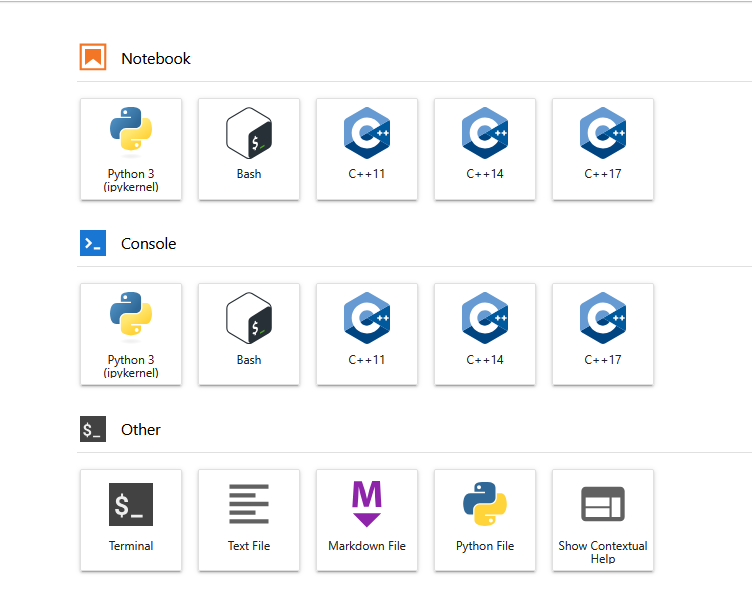

In [17]:
cpp_kernel

In [18]:
#include<string>

std::string name = "Gobal Krishnan V";
name

"Gobal Krishnan V"